# XGBoost — Strategy A

**Why XGBoost after RF?** Gradient boosting builds trees sequentially (each corrects the previous ensemble's errors), while RF builds them independently. This gives XGBoost:
- Better handling of class imbalance by default (boosting focuses on hard examples).
- Stronger performance on tabular data — typically +0.03–0.06 macro F1 over RF.
- Built-in regularization (shrinkage, column subsampling, min_child_weight) that prevents overfitting to augmentation noise.

**Hyperparameters** are mid-range defaults, intentionally untuned:
- `n_estimators=300`, `max_depth=6`, `learning_rate=0.1`
- `subsample=0.8`, `colsample_bytree=0.8` — mild stochasticity
- `min_child_weight=5` — prevents rare-class overfitting
- `tree_method='hist'` — fast histogram binning

**Two configs** (same pattern as RF):
1. Vanilla XGBoost, threshold 0.5
2. XGBoost + per-class threshold tuning on val

**No class weighting config.** LogReg and RF both showed that class weighting hurts or is neutral; threshold tuning is the consistent lever. XGBoost's `scale_pos_weight` would be the analog — skipped here for the same reason.

**Expected runtime:** ~3–8 min on CPU. Faster than RF because trees are depth-limited (6 vs unlimited).

In [1]:
# ============================================================================
# CELL 1 — Setup
# ============================================================================
import sys
from pathlib import Path

_SHARED = Path.cwd().resolve().parents[1] / '_shared'
if str(_SHARED) not in sys.path:
    sys.path.insert(0, str(_SHARED))

import json
import time
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from xgboost import XGBClassifier
except ImportError:
    raise ImportError(
        "xgboost not installed. Run: pip install xgboost\n"
        "  or: conda install -c conda-forge xgboost"
    )
from sklearn.multiclass import OneVsRestClassifier

from data import load_splits, find_root, load_config
from eval import (
    predict_with_threshold, tune_thresholds_on_val,
    classification_report,
)
from plot import plot_per_class_f1, plot_confusion_matrices

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# --- Config ---------------------------------------------------------------
STRATEGY    = 'A'
MODEL_NAME  = 'xgboost'
NOTEBOOK_ID = '05'
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Mid-range XGBoost defaults — not tuned
N_ESTIMATORS     = 300
MAX_DEPTH        = 6
LEARNING_RATE    = 0.1
SUBSAMPLE        = 0.8
COLSAMPLE_BYTREE = 0.8
MIN_CHILD_WEIGHT = 5
N_JOBS           = -1

# --- Paths ---------------------------------------------------------------
ROOT       = find_root()
CONFIG     = load_config()
ARTIFACTS  = ROOT / CONFIG['paths'][f'strategy_{STRATEGY.lower()}_artifacts']
RESULTS_DIR = ARTIFACTS / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Strategy:      {STRATEGY}")
print(f"Model:         {MODEL_NAME}")
print(f"Hyperparams:   n_est={N_ESTIMATORS}, depth={MAX_DEPTH}, lr={LEARNING_RATE}, "
      f"subsample={SUBSAMPLE}, colsample={COLSAMPLE_BYTREE}, min_child={MIN_CHILD_WEIGHT}")
print(f"Results dir:   {RESULTS_DIR}")

Strategy:      A
Model:         xgboost
Hyperparams:   n_est=300, depth=6, lr=0.1, subsample=0.8, colsample=0.8, min_child=5
Results dir:   /Users/amrabdullah/AI_2026ss/mlpc/strategy_A_baseline/artifacts/results


In [2]:
# ============================================================================
# CELL 2 — Load data
# ============================================================================
d = load_splits(STRATEGY)
print(d.summary())

class_names = list(d.class_names)

print(f"\nPositive rate per class (train):")
for c, cls in enumerate(class_names):
    rate = d.Y_train[:, c].mean()
    print(f"  {cls:<30s}  {rate*100:>6.2f}%  ({int(d.Y_train[:, c].sum()):>6,d} positives)")

Strategy A
  X_train: (100166, 960)  Y_train: (100166, 15)
  X_val:   (34245, 960)  Y_val:   (34245, 15)
  X_test:  (33828, 960)  Y_test:  (33828, 15)
  D = 960 features, C = 15 classes

Positive rate per class (train):
  bell_ringing                      1.09%  ( 1,091 positives)
  coffee_machine                    3.78%  ( 3,788 positives)
  cutlery_dishes                    6.03%  ( 6,039 positives)
  door_open_close                   3.57%  ( 3,578 positives)
  footsteps                        11.41%  (11,433 positives)
  keyboard_typing                   9.11%  ( 9,123 positives)
  keychain                          4.56%  ( 4,570 positives)
  light_switch                      0.27%  (   273 positives)
  microwave                         6.81%  ( 6,823 positives)
  phone_ringing                     6.26%  ( 6,273 positives)
  running_water                    12.82%  (12,846 positives)
  toilet_flushing                   3.16%  ( 3,170 positives)
  vacuum_cleaner                    

## Cell 3 — Train XGBoost

Wrapped in `OneVsRestClassifier` for multi-label — same pattern as LogReg. Each of the 15 classes gets its own binary XGBoost trained independently.

XGBoost's `verbosity=0` suppresses its internal logging. Training progress comes from our own timing.

In [3]:
# ============================================================================
# CELL 3 — Train
# ============================================================================
t0 = time.time()
model = OneVsRestClassifier(
    XGBClassifier(
        n_estimators=N_ESTIMATORS,
        max_depth=MAX_DEPTH,
        learning_rate=LEARNING_RATE,
        subsample=SUBSAMPLE,
        colsample_bytree=COLSAMPLE_BYTREE,
        min_child_weight=MIN_CHILD_WEIGHT,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        verbosity=0,
        random_state=RANDOM_SEED,
        n_jobs=1,          # inner parallelism per tree
    ),
    n_jobs=N_JOBS,         # outer parallelism across classes
)
model.fit(d.X_train, d.Y_train)
elapsed = time.time() - t0
print(f"XGBoost trained in {elapsed/60:.1f} min  ({elapsed:.0f}s)")

# Val probabilities
val_probs = model.predict_proba(d.X_val)
print(f"Val probs shape: {val_probs.shape}")

XGBoost trained in 10.7 min  (643s)
Val probs shape: (34245, 15)


## Cell 4 — Evaluate on val

- **Config 1**: threshold 0.5 (vanilla).
- **Config 2**: per-class thresholds tuned on val (same model, different decision rule).

XGBoost probabilities are better calibrated than RF (sigmoid output from logistic objective), so the Config 1 → Config 2 gap should be smaller than RF's dramatic jump. But threshold tuning still helps for rare classes whose optimal threshold is well below 0.5.

In [4]:
# ============================================================================
# CELL 4 — Evaluate on val
# ============================================================================
# Config 1 — vanilla, threshold 0.5
Y_val_pred_1 = predict_with_threshold(val_probs, 0.5)
report_val_1 = classification_report(d.Y_val, Y_val_pred_1, class_names)

# Config 2 — per-class thresholds tuned on val
threshold_df = tune_thresholds_on_val(val_probs, d.Y_val, class_names=class_names)
thresholds_2 = threshold_df['threshold'].loc[class_names].values
Y_val_pred_2 = predict_with_threshold(val_probs, thresholds_2)
report_val_2 = classification_report(d.Y_val, Y_val_pred_2, class_names)

print("=== VAL RESULTS ===\n")
print(f"  {'config':<40s}  {'macro_f1':>9s}  {'micro_f1':>9s}")
for name, rep in [
    ("1 - vanilla XGBoost (th=0.5)", report_val_1),
    ("2 - XGBoost + tuned thresholds", report_val_2),
]:
    m = rep.loc['macro avg', 'f1']
    u = rep.loc['micro avg', 'f1']
    print(f"  {name:<40s}  {m:>9.4f}  {u:>9.4f}")

print(f"\n=== Tuned thresholds (Config 2) ===")
print(threshold_df[['threshold', 'val_f1', 'val_support']].to_string())

=== VAL RESULTS ===

  config                                     macro_f1   micro_f1
  1 - vanilla XGBoost (th=0.5)                 0.4714     0.6019
  2 - XGBoost + tuned thresholds               0.5517     0.6355

=== Tuned thresholds (Config 2) ===
                            threshold  val_f1  val_support
class                                                     
bell_ringing                     0.14  0.4943          480
coffee_machine                   0.27  0.6189         1073
cutlery_dishes                   0.22  0.5933         1828
door_open_close                  0.12  0.3633         1177
footsteps                        0.21  0.5276         4033
keyboard_typing                  0.23  0.7550         3107
keychain                         0.23  0.6180         1553
light_switch                     0.06  0.1547          140
microwave                        0.21  0.6737         2253
phone_ringing                    0.18  0.6755         2122
running_water                    0.35  

In [5]:
# ============================================================================
# CELL 5 — Per-class F1 comparison
# ============================================================================
comparison = pd.DataFrame({
    'config_1_vanilla': report_val_1.loc[class_names, 'f1'],
    'config_2_tuned':   report_val_2.loc[class_names, 'f1'],
    'support':          report_val_1.loc[class_names, 'support'],
})
comparison['gain_tuned'] = (comparison['config_2_tuned'] - comparison['config_1_vanilla']).round(4)
comparison = comparison.sort_values('support', ascending=True)

print("=== Per-class F1 by config (sorted rare -> common) ===\n")
print(comparison.to_string())

=== Per-class F1 by config (sorted rare -> common) ===

                            config_1_vanilla  config_2_tuned  support  gain_tuned
class                                                                            
light_switch                          0.0141          0.1547    140.0      0.1406
window_open_close                     0.1229          0.3077    421.0      0.1848
bell_ringing                          0.4145          0.4943    480.0      0.0798
wardrobe_drawer_open_close            0.0782          0.2830    613.0      0.2048
toilet_flushing                       0.6642          0.6796    967.0      0.0154
coffee_machine                        0.6000          0.6189   1073.0      0.0189
door_open_close                       0.1961          0.3633   1177.0      0.1672
keychain                              0.5780          0.6180   1553.0      0.0400
cutlery_dishes                        0.5298          0.5933   1828.0      0.0635
phone_ringing                         0.63

## Cell 6 — Pick winner, run test once

In [6]:
# ============================================================================
# CELL 6 — Pick winner on val, evaluate on test
# ============================================================================
val_scores = {
    1: report_val_1.loc['macro avg', 'f1'],
    2: report_val_2.loc['macro avg', 'f1'],
}
winner = max(val_scores, key=val_scores.get)
print(f"Winner on val: Config {winner} (macro F1 = {val_scores[winner]:.4f})\n")

if winner == 1:
    winning_thresholds = np.full(d.C, 0.5)
else:
    winning_thresholds = thresholds_2

test_probs = model.predict_proba(d.X_test)
Y_test_pred = predict_with_threshold(test_probs, winning_thresholds)
report_test = classification_report(d.Y_test, Y_test_pred, class_names)

print(f"=== TEST RESULTS (Config {winner}) ===")
print(report_test.round(4).to_string())

Winner on val: Config 2 (macro F1 = 0.5517)

=== TEST RESULTS (Config 2) ===
                            precision  recall      f1  support
class                                                         
bell_ringing                   0.7743  0.5114  0.6160    483.0
coffee_machine                 0.7924  0.4879  0.6039   1236.0
cutlery_dishes                 0.6169  0.6685  0.6416   2045.0
door_open_close                0.3242  0.5051  0.3949   1077.0
footsteps                      0.5213  0.6017  0.5586   4256.0
keyboard_typing                0.7785  0.6907  0.7320   3333.0
keychain                       0.6024  0.6024  0.6024   1474.0
light_switch                   0.0909  0.0682  0.0779     88.0
microwave                      0.7196  0.6747  0.6964   2579.0
phone_ringing                  0.6693  0.7009  0.6847   2076.0
running_water                  0.7553  0.8286  0.7903   4190.0
toilet_flushing                0.8106  0.5967  0.6874   1076.0
vacuum_cleaner                 0.6935  0.

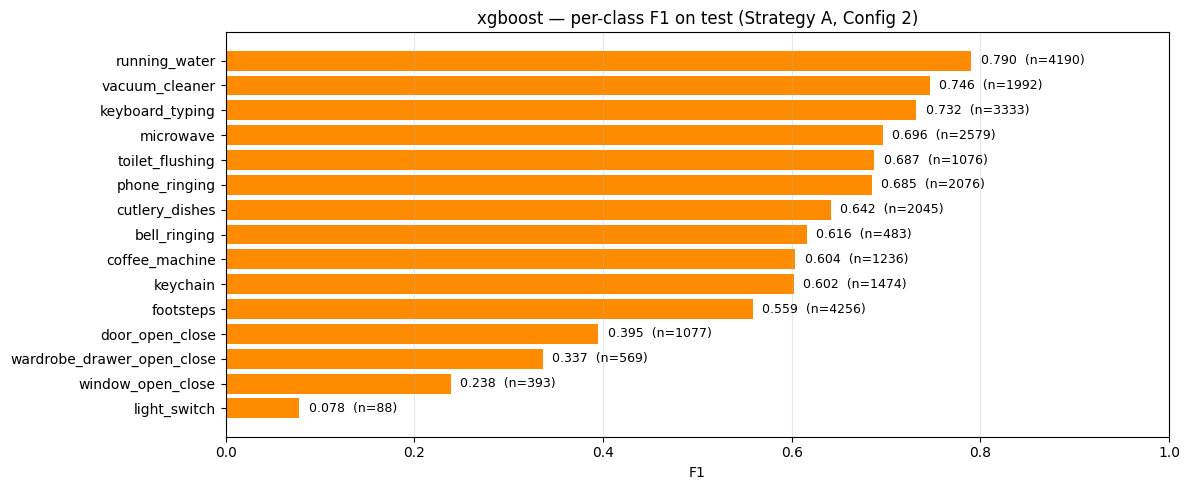

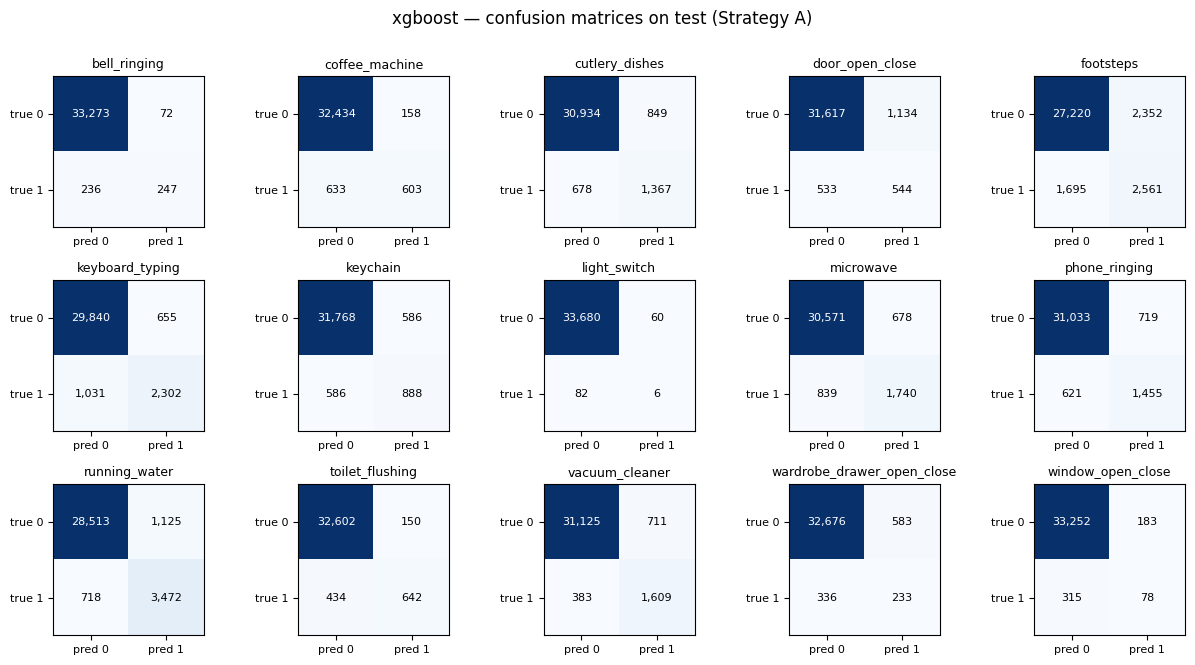

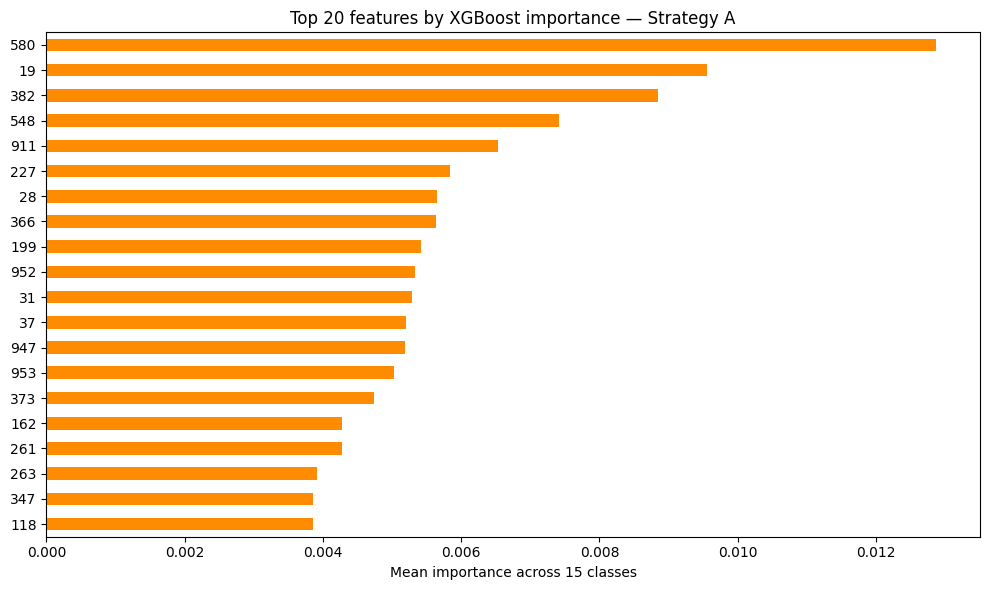

In [7]:
# ============================================================================
# CELL 7 — Plots
# ============================================================================
fig, ax = plot_per_class_f1(
    report_test, class_names=class_names,
    title=f"{MODEL_NAME} — per-class F1 on test (Strategy {STRATEGY}, Config {winner})",
    color='darkorange',
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_per_class_f1.png",
            dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plot_confusion_matrices(
    d.Y_test, Y_test_pred, class_names=class_names,
    title=f"{MODEL_NAME} — confusion matrices on test (Strategy {STRATEGY})",
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_confusion.png",
            dpi=150, bbox_inches='tight')
plt.show()

# --- Feature importances (XGBoost gives us this too) ---
# OvR wraps 15 estimators — average their importances
fi_raw = np.array([est.feature_importances_ for est in model.estimators_])  # (15, D)
fi_avg = fi_raw.mean(axis=0)

# Map to feature group names if dimensionality allows
if len(d.feature_names) == d.D:
    idx_labels = d.feature_names
else:
    idx_labels = [str(i) for i in range(d.D)]

fi = pd.Series(fi_avg, index=idx_labels).sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(10, 6))
fi.iloc[::-1].plot.barh(ax=ax, color='darkorange')
ax.set_xlabel('Mean importance across 15 classes')
ax.set_title(f'Top 20 features by XGBoost importance — Strategy {STRATEGY}')
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_top_features.png",
            dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# ============================================================================
# CELL 8 — Save results
# ============================================================================
def df_to_jsonable(df):
    return {idx: {col: (int(v) if col == 'support' else float(v))
                  for col, v in row.items()}
            for idx, row in df.iterrows()}

results = {
    'meta': {
        'strategy':         STRATEGY,
        'model':            MODEL_NAME,
        'notebook_id':      NOTEBOOK_ID,
        'timestamp':        datetime.now().isoformat(timespec='seconds'),
        'random_seed':      RANDOM_SEED,
        'training_seconds': round(elapsed, 2),
        'n_train':          int(d.N_train),
        'n_val':            int(d.N_val),
        'n_test':           int(d.N_test),
    },
    'winning_config': {
        'config_id':       int(winner),
        'description':     [
            "1 - vanilla XGBoost (threshold 0.5)",
            "2 - XGBoost + per-class thresholds tuned on val",
        ][winner - 1],
        'thresholds':      [float(t) for t in winning_thresholds],
        'hyperparameters': {
            'n_estimators':     N_ESTIMATORS,
            'max_depth':        MAX_DEPTH,
            'learning_rate':    LEARNING_RATE,
            'subsample':        SUBSAMPLE,
            'colsample_bytree': COLSAMPLE_BYTREE,
            'min_child_weight': MIN_CHILD_WEIGHT,
            'objective':        'binary:logistic',
            'tree_method':      'hist',
        },
    },
    'val_scores_macro_f1': {f'config_{k}': float(v) for k, v in val_scores.items()},
    'val_report':  df_to_jsonable(report_val_2 if winner == 2 else report_val_1),
    'test_report': df_to_jsonable(report_test),
    'headline_test': {
        'macro_f1':    float(report_test.loc['macro avg', 'f1']),
        'micro_f1':    float(report_test.loc['micro avg', 'f1']),
        'weighted_f1': float(report_test.loc['weighted avg', 'f1']),
    },
}

out_path = RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}.json"
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Saved: {out_path}")
print(f"\n=== HEADLINE ===")
print(f"  Strategy {STRATEGY} / {MODEL_NAME} / Config {winner}")
print(f"  Test macro F1:    {results['headline_test']['macro_f1']:.4f}")
print(f"  Test micro F1:    {results['headline_test']['micro_f1']:.4f}")
print(f"  Test weighted F1: {results['headline_test']['weighted_f1']:.4f}")
print(f"\nReference points:")
print(f"  Random (stratified):  ~0.05 macro F1  (floor)")
print(f"  LogReg A:              0.4723 macro F1")
print(f"  LogReg B:              0.4749 macro F1")
print(f"  RF A:                  0.5040 macro F1")
print(f"  RF B:                  0.4982 macro F1")

Saved: /Users/amrabdullah/AI_2026ss/mlpc/strategy_A_baseline/artifacts/results/05_xgboost.json

=== HEADLINE ===
  Strategy A / xgboost / Config 2
  Test macro F1:    0.5605
  Test micro F1:    0.6497
  Test weighted F1: 0.6526

Reference points:
  Random (stratified):  ~0.05 macro F1  (floor)
  LogReg A:              0.4723 macro F1
  LogReg B:              0.4749 macro F1
  RF A:                  0.5040 macro F1
  RF B:                  0.4982 macro F1
